# Climate & Health Risk Prediction Challenge

This is  a Zindi Comptition challenge   https://zindi.world/  


Using health, demographic, geographic, and climate-related data, we will identify patterns that can help improve our understanding of how environmental conditions may contribute to mortality.

Competition Link: https://zindi.world/competitions/climate-risk-health-prediction-challenge





## Evaluation metric
Final Score = 0.60 * F1 + 0.40 * ROC-AUC




In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elkanahrutto/climate-health-risk/climate_features.csv
/kaggle/input/datasets/elkanahrutto/climate-health-risk/Train (9).csv
/kaggle/input/datasets/elkanahrutto/climate-health-risk/Test (9).csv


In [3]:
# import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

In [4]:

# Load main competition data

train = pd.read_csv("/kaggle/input/datasets/elkanahrutto/climate-health-risk/Train (9).csv")
test = pd.read_csv("/kaggle/input/datasets/elkanahrutto/climate-health-risk/Test (9).csv")

# Load downloaded climate/environmental features
# This file should contain one row per ID
climate_features = pd.read_csv("/kaggle/input/datasets/elkanahrutto/climate-health-risk/climate_features.csv")

ID_COL = "ID"
TARGET = "is_climate_sensitive"
TARGET_F1 = "TargetF1"
TARGET_RAUC = "TargetRAUC"

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Climate feature shape:", climate_features.shape)

train.head()


Train shape: (3146, 13)
Test shape: (1030, 12)
Climate feature shape: (4176, 18)


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,10/2/2007,30,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,1/5/2008,2,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2/14/2008,31,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2/15/2008,1,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2/15/2008,69,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


# Merging climate features

Here we merge provided features in train/test with additional climate features to give model more information and improve prediction 

In [5]:


## Drop deathdate from climate_features
climate_features = climate_features.drop(columns=["deathdate"])


In [6]:

# Merge on ID
train = train.merge(climate_features, on=ID_COL, how="left")
test = test.merge(climate_features, on=ID_COL, how="left")

print("Train shape after merge:", train.shape)
print("Test shape after merge:", test.shape)

# Create a sample submission template from the test IDs
sample_submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET_F1: 0,
    TARGET_RAUC: 0.5
})

sample_submission.head()


Train shape after merge: (3146, 29)
Test shape after merge: (1030, 28)


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.5
1,ID_6EDEA907,0,0.5
2,ID_B9FFC8D8,0,0.5
3,ID_74C6C94E,0,0.5
4,ID_0E02825D,0,0.5


# Explanatory Data Analysis

Get to understand the distribution of each feature and how it may affect model prediction

In [7]:
# Check for Null, Data type and number of rows
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   int64  
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
 13  elevation             3146 non-null   int64  
 14  hot_days_30d          3146 non-null   int64  
 15  max_daily_rain_30d   

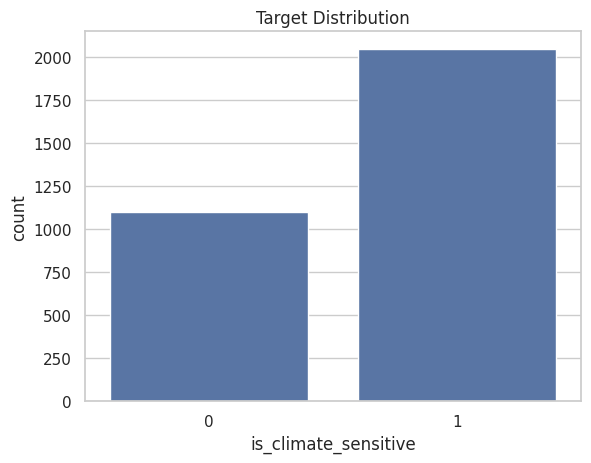

is_climate_sensitive
1    0.650668
0    0.349332
Name: proportion, dtype: float64

In [8]:
# Target distribution
sns.countplot(x=TARGET, data=train)
plt.title("Target Distribution")
plt.show()


train[TARGET].value_counts(normalize=True)


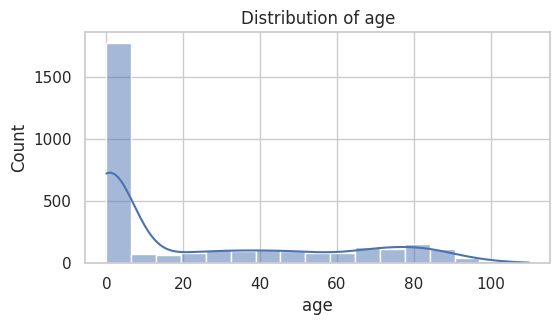

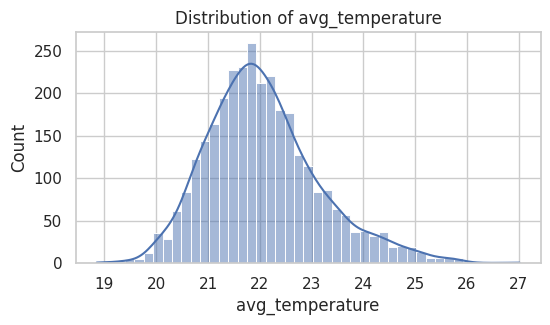

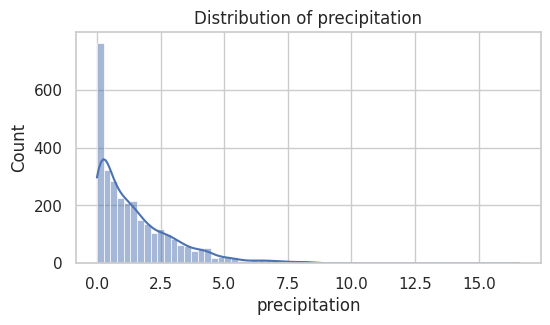

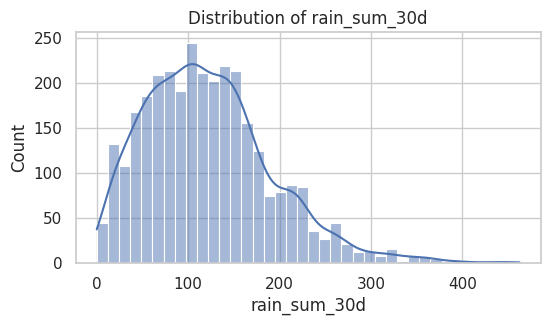

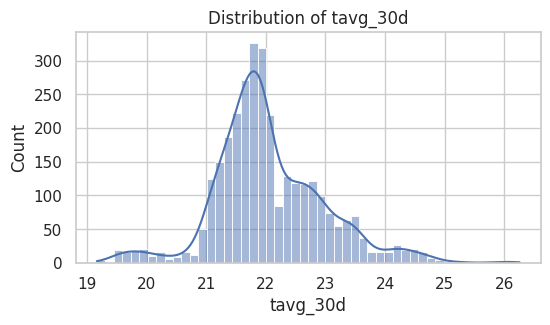

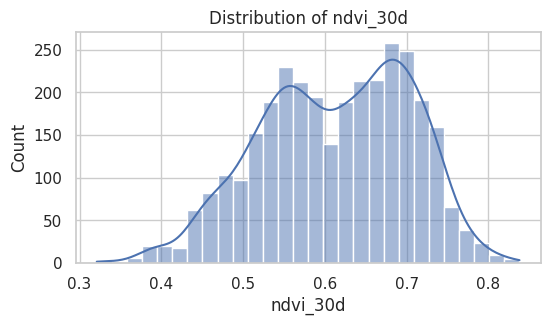

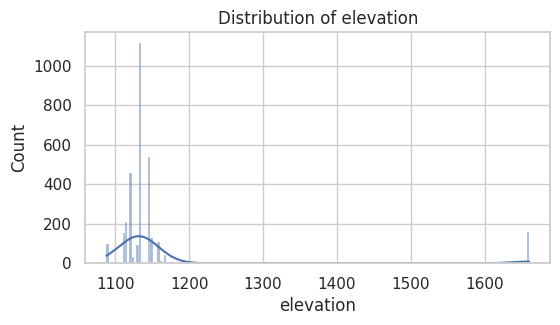

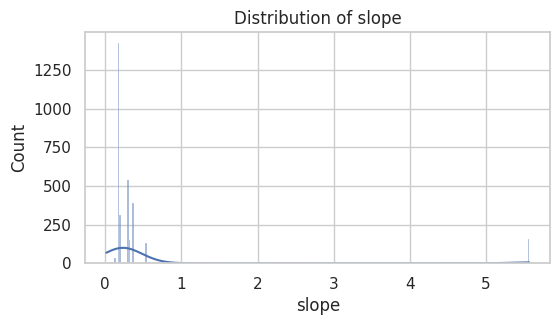

In [9]:

# Inspect some original and downloaded climate features
features_to_plot = [
    "age",
    "avg_temperature",
    "precipitation",
    "rain_sum_30d",
    "tavg_30d",
    "ndvi_30d",
    "elevation",
    "slope"
]

for col in features_to_plot:
    if col in train.columns:
        plt.figure(figsize=(6, 3))
        sns.histplot(train[col].dropna(), kde=True)
        plt.title(f"Distribution of {col}")
        plt.show()


# Preprocessing and Feature Engineering

Engineering the available features to prepare data for training and also obtain more featurs to help in prediction

In [33]:
train_df = train.copy()
test_df = test.copy()

In [34]:
# Derived columns
#train
# train_df["temp_range"] = train_df["max_temperature"] - train_df["min_temperature"]
# train_df["rain_intensity_30d"] = train_df["rain_sum_30d"] / train_df["rain_days_30d"].replace(0, np.nan)
train_df["rain_ratio_7_30"] = train_df["rain_sum_7d"] / train_df["rain_sum_30d"].replace(0, np.nan)
# train_df["rain_ratio_30_90"] = train_df["rain_sum_30d"] / train_df["rain_sum_90d"].replace(0, np.nan)
# train_df["temp_change_30_90"] = train_df["tavg_30d"] - train_df["tavg_90d"]
# train_df["temp_change_7_30"] = train_df["tavg_7d"] - train_df["tavg_30d"]
# train_df["ndvi_change"] = train_df["ndvi_30d"] - train_df["ndvi_90d"]

# #test
# test_df["temp_range"] = test_df["max_temperature"] - test_df["min_temperature"]
# test_df["rain_intensity_30d"] = test_df["rain_sum_30d"] / test_df["rain_days_30d"].replace(0, np.nan)
test_df["rain_ratio_7_30"] = test_df["rain_sum_7d"] / test_df["rain_sum_30d"].replace(0, np.nan)
# test_df["rain_ratio_30_90"] = test_df["rain_sum_30d"] / test_df["rain_sum_90d"].replace(0, np.nan)
# test_df["temp_change_30_90"] = test_df["tavg_30d"] - test_df["tavg_90d"]
# test_df["temp_change_7_30"] = test_df["tavg_7d"] - test_df["tavg_30d"]
# test_df["ndvi_change"] = test_df["ndvi_30d"] - test_df["ndvi_90d"]


# Convert deathdate to datetime
train_df["deathdate"] = pd.to_datetime(train_df["deathdate"])
test_df["deathdate"] = pd.to_datetime(test_df["deathdate"])

# Extract date features
train_df["year"] = train_df["deathdate"].dt.year
test_df["year"] = test_df["deathdate"].dt.year

train_df["month"] = train_df["deathdate"].dt.month
test_df["month"] = test_df["deathdate"].dt.month

train_df["dayofyear"] = train_df["deathdate"].dt.dayofyear
test_df["dayofyear"] = test_df["deathdate"].dt.dayofyear

train_df["quarter"] = train_df["deathdate"].dt.quarter
test_df["quarter"] = test_df["deathdate"].dt.quarter


#mapping gender to numerical
train_df['gender'] = train_df['gender'].map({
    'Male': 1,
    'Female': 0
})

test_df['gender'] = test_df['gender'].map({
    'Male': 1,
    'Female': 0
})

#Encoding  zone column
train_df['zone'] = train_df['zone'].map({
    'Rural': 1,
    'Peri_urban': 0
})
test_df['zone'] = test_df['zone'].map({
    'Rural': 1,
    'Peri_urban': 0
})

train_df.head()


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,rain_ratio_7_30,year,month,dayofyear,quarter
0,ID_1FE951BD,1,1,2007-10-02,30,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,0.162150,2007,10,275,4
1,ID_5927A443,1,1,2008-01-05,2,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439277,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,0.000000,2008,1,5,1
2,ID_C4E67025,1,0,2008-02-14,31,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,0.332612,2008,2,45,1
3,ID_44DC5CE9,1,0,2008-02-15,1,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,0.295267,2008,2,46,1
4,ID_33C677BB,1,0,2008-02-15,69,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,0.305826,2008,2,46,1


In [35]:
# Derived Columns

# create categories for age 
bins = [0,1,10, 18, 60, 200]
labels = [
    "Infant",
    "Child",
    "Teenager",
    "Adult",
    "Elderly"
]

train_df["age_cat"] = pd.cut(
    train_df["age"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

test_df["age_cat"] = pd.cut(
    test_df["age"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

age_mapping = {
    "Infant": 0,
    "Child": 1,
    "Teenager": 2,
    "Adult": 3,
    "Elderly": 4
}


train_df["age_cat"] = train_df["age_cat"].map(age_mapping).astype("Int64")
test_df["age_cat"] = test_df["age_cat"].map(age_mapping).astype("Int64")


train_df.head(200)

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,rain_ratio_7_30,year,month,dayofyear,quarter,age_cat
0,ID_1FE951BD,1,1,2007-10-02,30,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,0.162150,2007,10,275,4,3
1,ID_5927A443,1,1,2008-01-05,2,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439277,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,0.000000,2008,1,5,1,1
2,ID_C4E67025,1,0,2008-02-14,31,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,0.332612,2008,2,45,1,3
3,ID_44DC5CE9,1,0,2008-02-15,1,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,0.295267,2008,2,46,1,0
4,ID_33C677BB,1,0,2008-02-15,69,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,0.305826,2008,2,46,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,ID_E4E6EEA5,1,1,2009-03-02,23,22.047662,26.308331,18.418833,1.001533,0.574287,33.538210,"Wairama, Iganga, Uganda",0,1122,0,9.432082,0.60510,0.57360,12,53.873548,16.495617,135.480300,0.356825,22.865134,23.413763,22.651420,8.651159,30.001230,17.101907,0.306191,2009,3,61,1,3
196,ID_1657FBB7,0,1,2009-03-03,97,23.073477,27.656148,19.080411,0.311123,0.605119,33.475691,"Kasokoso South, Iganga, Uganda",0,1132,0,9.068101,0.50005,0.46070,12,52.865327,14.419528,133.529570,0.166667,22.901552,23.349212,22.653308,8.699844,30.001230,17.101907,0.272760,2009,3,62,1,4
197,ID_4C614225,0,1,2009-03-04,79,23.582334,28.362721,19.613267,0.346498,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",0,1132,0,21.664780,0.50005,0.46070,12,71.507407,34.166435,155.194350,0.166667,22.929442,23.382141,22.671940,8.670550,30.001230,17.739816,0.477803,2009,3,63,1,4
198,ID_C6E39914,1,1,2009-03-05,1,23.174166,26.521133,19.756702,1.069399,0.526398,33.519818,"Buwaiswa, Mayuge, Uganda",1,1157,0,13.287192,0.58240,0.56380,10,55.769664,23.252585,150.816395,0.324049,22.851858,23.226932,22.579400,7.720487,29.206308,18.209344,0.416940,2009,3,64,1,0


In [36]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID                    3146 non-null   object        
 1   zone                  3146 non-null   int64         
 2   gender                3146 non-null   int64         
 3   deathdate             3146 non-null   datetime64[ns]
 4   age                   3146 non-null   int64         
 5   avg_temperature       3146 non-null   float64       
 6   max_temperature       3146 non-null   float64       
 7   min_temperature       3146 non-null   float64       
 8   precipitation         3146 non-null   float64       
 9   latitude              3146 non-null   float64       
 10  longitude             3146 non-null   float64       
 11  location              3146 non-null   object        
 12  is_climate_sensitive  3146 non-null   int64         
 13  elevation         

In [38]:
#fill NaN  with mean

# train_df["rain_intensity_30d"] = train_df["rain_intensity_30d"].fillna(train_df["rain_intensity_30d"].mean())
train_df["rain_ratio_7_30"] = train_df["rain_ratio_7_30"].fillna(train_df["rain_ratio_7_30"].mean())

# test_df["rain_intensity_30d"] = test_df["rain_intensity_30d"].fillna(test_df["rain_intensity_30d"].mean())
test_df["rain_ratio_7_30"] = test_df["rain_ratio_7_30"].fillna(test_df["rain_ratio_7_30"].mean())

In [39]:
#recheck to ensure there is no NaN
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID                    3146 non-null   object        
 1   zone                  3146 non-null   int64         
 2   gender                3146 non-null   int64         
 3   deathdate             3146 non-null   datetime64[ns]
 4   age                   3146 non-null   int64         
 5   avg_temperature       3146 non-null   float64       
 6   max_temperature       3146 non-null   float64       
 7   min_temperature       3146 non-null   float64       
 8   precipitation         3146 non-null   float64       
 9   latitude              3146 non-null   float64       
 10  longitude             3146 non-null   float64       
 11  location              3146 non-null   object        
 12  is_climate_sensitive  3146 non-null   int64         
 13  elevation         

In [40]:
# Define target and features
X = train_df.drop(columns=[ TARGET, ID_COL, "location", "latitude", "longitude", "elevation", "deathdate", "slope", "hot_days_30d", "max_daily_rain_30d",
                           "tavg_7d", "max_temperature", "min_temperature", "tmax_30d", "tmin_30d", "temp_range_mean_30d", "rain_days_30d", "month"])
y = train_df[TARGET]

X_test = test_df.drop(columns=[ID_COL, "location", "latitude", "longitude","elevation", "deathdate", "slope", "hot_days_30d", "max_daily_rain_30d",
                           "tavg_7d", "max_temperature", "min_temperature", "tmax_30d", "tmin_30d", "temp_range_mean_30d", "rain_days_30d", "month"])

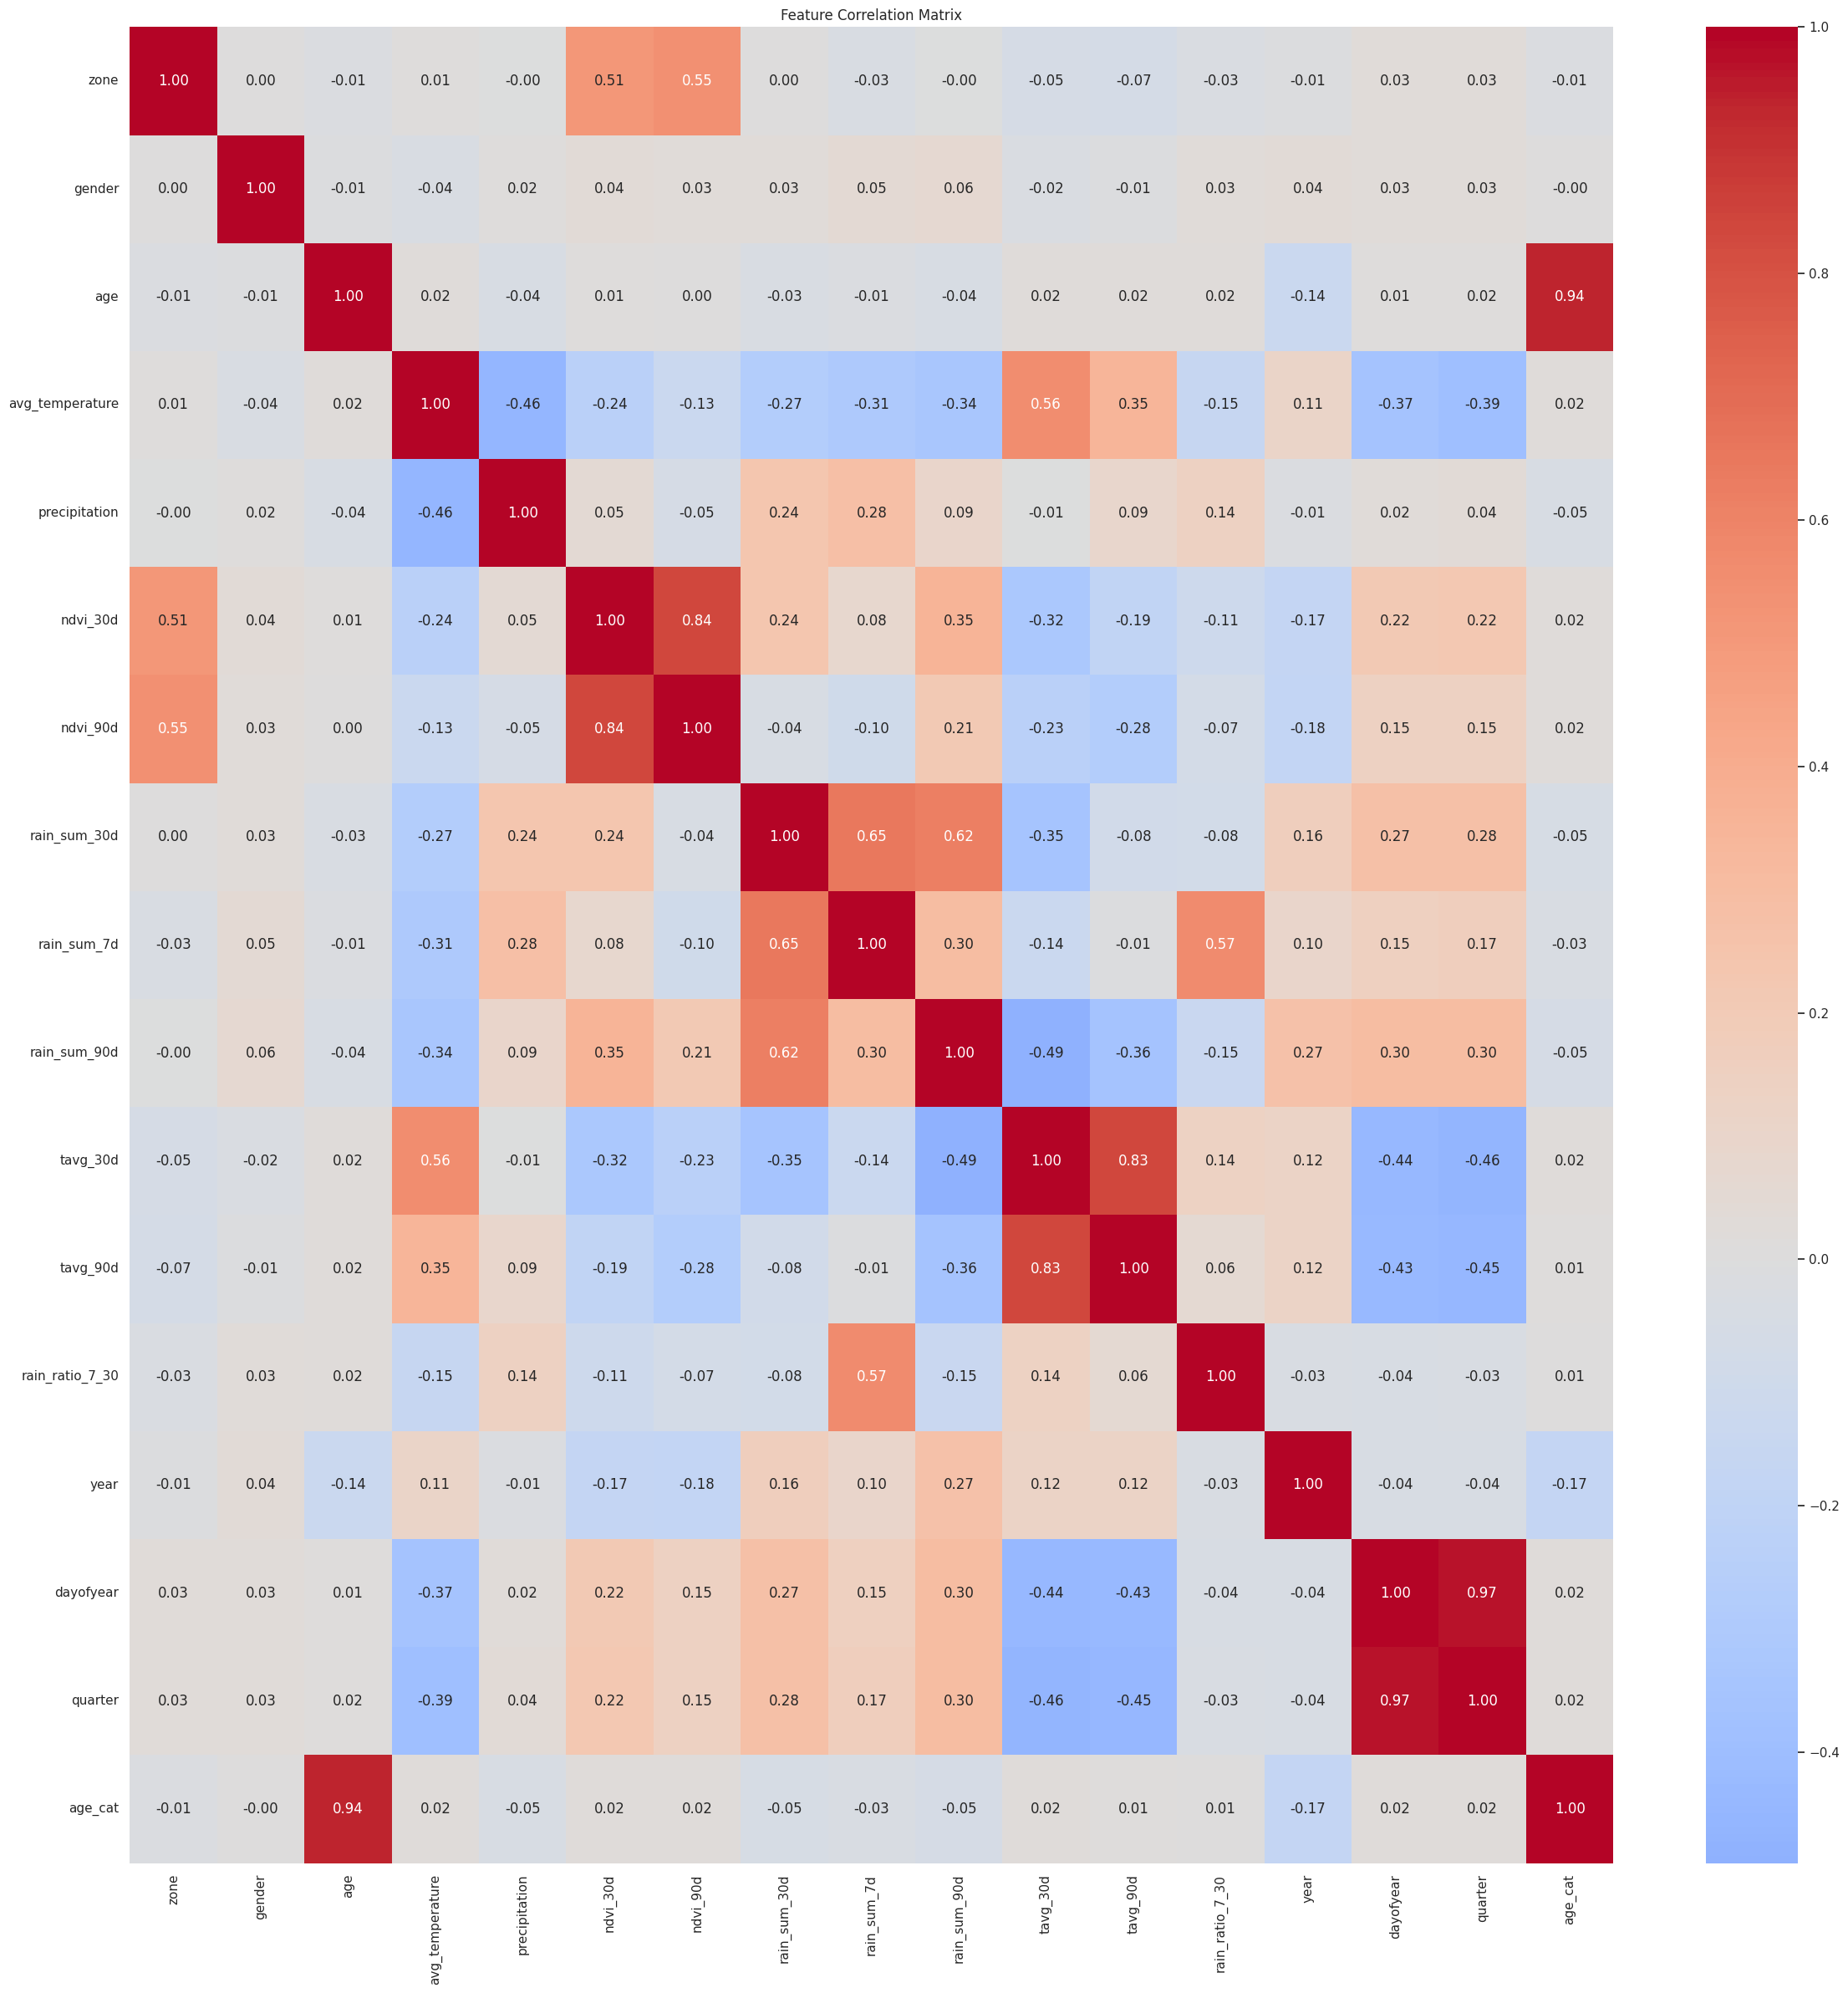

In [41]:
#Draw Correlation matrix to clearly see features correlation


import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix
corr_matrix = X.corr(numeric_only=True)

plt.figure(figsize=(24, 24))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# Training and Validation

Choose to work with Catboost Classifier

In [42]:
# validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)


X_train shape: (2516, 17)
X_val shape: (630, 17)


In [43]:
from catboost import CatBoostClassifier
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score, roc_auc_score, precision_score, recall_score, accuracy_score
)


# 5-fold CV with CatBoost 

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

oof_prob = np.zeros(len(X))          # out-of-fold probabilities
test_prob = np.zeros(len(X_test))    # averaged test probabilities

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

    cat = CatBoostClassifier(
        iterations=10000,
        learning_rate=0.03,
        eval_metric="AUC",
        early_stopping_rounds=150,
        random_seed=1,
        verbose=0
    )
    cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)

    oof_prob[va_idx] = cat.predict_proba(X_va)[:, 1]
    test_prob += cat.predict_proba(X_test)[:, 1] / N_SPLITS

    print(f"Fold {fold}: AUC = {roc_auc_score(y_va, oof_prob[va_idx]):.4f}, "
          f"best_iter = {cat.get_best_iteration()}")


# Find best threshold for F1 on ALL out-of-fold predictions
thresholds = np.arange(0.10, 0.91, 0.01)
f1_scores = [f1_score(y, (oof_prob >= t).astype(int)) for t in thresholds]

best_threshold = thresholds[int(np.argmax(f1_scores))]
best_f1 = max(f1_scores)


# Metrics on out-of-fold predictions
oof_pred = (oof_prob >= best_threshold).astype(int)

accuracy  = accuracy_score(y, oof_pred)
precision = precision_score(y, oof_pred)
recall    = recall_score(y, oof_pred)
f1        = f1_score(y, oof_pred)
roc_auc   = roc_auc_score(y, oof_prob)       # probabilities, not labels
final_score = 0.60 * f1 + 0.40 * roc_auc

print("\n--- CatBoost 5-Fold CV Results ---")
print("Threshold :", round(best_threshold, 2))
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1-Score  :", f1)
print("ROC-AUC   :", roc_auc)
print("Final Score (60% F1 + 40% ROC-AUC):", final_score)

Fold 1: AUC = 0.8407, best_iter = 54
Fold 2: AUC = 0.8346, best_iter = 148
Fold 3: AUC = 0.8260, best_iter = 224
Fold 4: AUC = 0.8024, best_iter = 171
Fold 5: AUC = 0.8053, best_iter = 84

--- CatBoost 5-Fold CV Results ---
Threshold : 0.45
Accuracy  : 0.7495232040686586
Precision : 0.7670767925328807
Recall    : 0.8832437713727406
F1-Score  : 0.821071752951862
ROC-AUC   : 0.8190827652086788
Final Score (60% F1 + 40% ROC-AUC): 0.8202761578545887


In [44]:
# CatBoost Feature Importance

importance = cat.get_feature_importance()

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("\n--- CatBoost Feature Importance ---")
print(feature_importance)


--- CatBoost Feature Importance ---
            Feature  Importance
13             year   29.299385
2               age   27.241477
16          age_cat   16.035177
6          ndvi_90d    3.336655
10         tavg_30d    2.804638
12  rain_ratio_7_30    2.582221
9      rain_sum_90d    2.523345
11         tavg_90d    2.412889
4     precipitation    2.204734
1            gender    1.953428
7      rain_sum_30d    1.909176
5          ndvi_30d    1.838393
8       rain_sum_7d    1.811975
3   avg_temperature    1.675968
14        dayofyear    1.425034
15          quarter    0.571570
0              zone    0.373936


In [45]:

# Test predictions

test_pred_proba = cat.predict_proba(X_test)[:, 1]

# Apply optimized F1 threshold
test_pred_label = (
    test_pred_proba >= best_threshold
).astype(int)

# Submission
submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET_F1: test_pred_label,
    TARGET_RAUC: test_pred_proba
})

# Save
submission.to_csv("submission.csv", index=False)

# Check
print(submission.head())
print("Submission shape:", submission.shape)

            ID  TargetF1  TargetRAUC
0  ID_E760D84B         0    0.412635
1  ID_6EDEA907         1    0.626485
2  ID_B9FFC8D8         1    0.495131
3  ID_74C6C94E         0    0.421685
4  ID_0E02825D         1    0.824230
Submission shape: (1030, 3)
